# 05 — Temporal Topic Modeling & Emerging-Threat Detection

Pipeline stage 5 of 5.

Loads `cleaned_reports.pkl` + `uploaded_docs.pkl`, builds a temporal corpus,
fits a 5-topic NMF model, tracks monthly topic shares, and flags emerging
patterns.

Saves:
- `artifacts/monthly_topic_shares.csv`
- `artifacts/emerging_threat_alerts.csv`


In [1]:

# ---------------------------------------------------------------------------
# Bootstrap — paths, imports, global config
# ---------------------------------------------------------------------------
import os
import re
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path(r"D:\Projects\done\thesis\ctc_ectd")
SCRIPTS_DIR  = PROJECT_ROOT / "scripts"
UPLOAD_DIR   = PROJECT_ROOT / "uploads"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

for d in (SCRIPTS_DIR, UPLOAD_DIR, ARTIFACT_DIR, PROCESSED_DIR):
    d.mkdir(parents=True, exist_ok=True)

if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (10, 5)
sns.set_theme(style="whitegrid")

print("PROJECT_ROOT :", PROJECT_ROOT)
print("PROCESSED_DIR:", PROCESSED_DIR)
print("ARTIFACT_DIR :", ARTIFACT_DIR)
print("UPLOAD_DIR   :", UPLOAD_DIR)


PROJECT_ROOT : D:\Projects\done\thesis\ctc_ectd
PROCESSED_DIR: D:\Projects\done\thesis\ctc_ectd\data\processed
ARTIFACT_DIR : D:\Projects\done\thesis\ctc_ectd\artifacts
UPLOAD_DIR   : D:\Projects\done\thesis\ctc_ectd\uploads


In [2]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

payload = pd.read_pickle(PROCESSED_DIR / "cleaned_reports.pkl")
df = payload["df"]
LABEL_COL = payload["LABEL_COL"]
DATE_COL  = payload["DATE_COL"]
uploaded_df = pd.read_pickle(PROCESSED_DIR / "uploaded_docs.pkl")

print("Training rows:", len(df), "| Uploaded docs:", len(uploaded_df))
print("DATE_COL:", DATE_COL)


Training rows: 10000 | Uploaded docs: 10
DATE_COL: date


## 1. Build temporal corpus

In [3]:

DATE_RE = re.compile(r"(20\d{2})[-_/](\d{1,2})")


def guess_date(row):
    m = DATE_RE.search(row.get("file_name", ""))
    if m:
        return pd.Timestamp(year=int(m.group(1)), month=int(m.group(2)), day=1)
    m = DATE_RE.search(str(row.get("text", ""))[:500])
    if m:
        return pd.Timestamp(year=int(m.group(1)), month=int(m.group(2)), day=1)
    return pd.NaT


if not uploaded_df.empty:
    docs = uploaded_df[uploaded_df["text"] != ""].copy()
    docs["parsed_date"] = docs.apply(guess_date, axis=1)
    docs["model_text"] = docs["text"]
    docs["source"] = "uploaded"
else:
    docs = pd.DataFrame(columns=["file_name", "text", "model_text",
                                 "parsed_date", "source"])

if DATE_COL is not None:
    df["parsed_date"] = pd.to_datetime(df[DATE_COL], errors="coerce")
else:
    df["parsed_date"] = pd.NaT
df["source"] = "training"

temporal_df = pd.concat(
    [df[["model_text", "parsed_date", "source", LABEL_COL]],
     docs.reindex(columns=["model_text", "parsed_date", "source", LABEL_COL])],
    ignore_index=True,
).dropna(subset=["parsed_date"]).copy()

temporal_df["month"] = (temporal_df["parsed_date"]
                        .dt.to_period("M").astype(str))

print("Temporal corpus size:", len(temporal_df))
print("Months covered:", temporal_df["month"].nunique())
print("Sources:", temporal_df["source"].value_counts().to_dict())


Temporal corpus size: 10010
Months covered: 69
Sources: {'training': 10000, 'uploaded': 10}


## 2. Fit NMF topics

Topic 1: activity, observed behavior, gain, targeted systems, malicious activity, gain access, mapped, affecting, behavior included, systems observed
Topic 2: activity, campaign, classified, additional activity, initial access, linked, initial, organizations recent, sector initial, severity observed
Topic 3: campaign used, monitoring, behavior involving, observed investigation, activity corresponds, investigation activity, intelligence monitoring, monitoring detected, detected, corresponds mitre
Topic 4: activity, sector located, investigation reported, campaign targeted, targeted organizations, located, reported mitre, reported, use, activity identified
Topic 5: web, attack, web attack, attack activity, identified web, detected web, attack behavior, involved web, attack incident, attack campaign


dominant_topic,1,2,3,4,5
month,,,,,
2021-01,0.237,0.216,0.230,0.223,0.094
2021-02,0.230,0.267,0.193,0.193,0.119
2021-03,0.181,0.239,0.219,0.271,0.090
2021-04,0.185,0.178,0.244,0.289,0.104
2021-05,0.218,0.211,0.256,0.241,0.075
...,...,...,...,...,...
2026-05,0.218,0.255,0.242,0.218,0.067
2026-06,0.205,0.225,0.205,0.272,0.093
2026-07,0.245,0.238,0.133,0.210,0.175


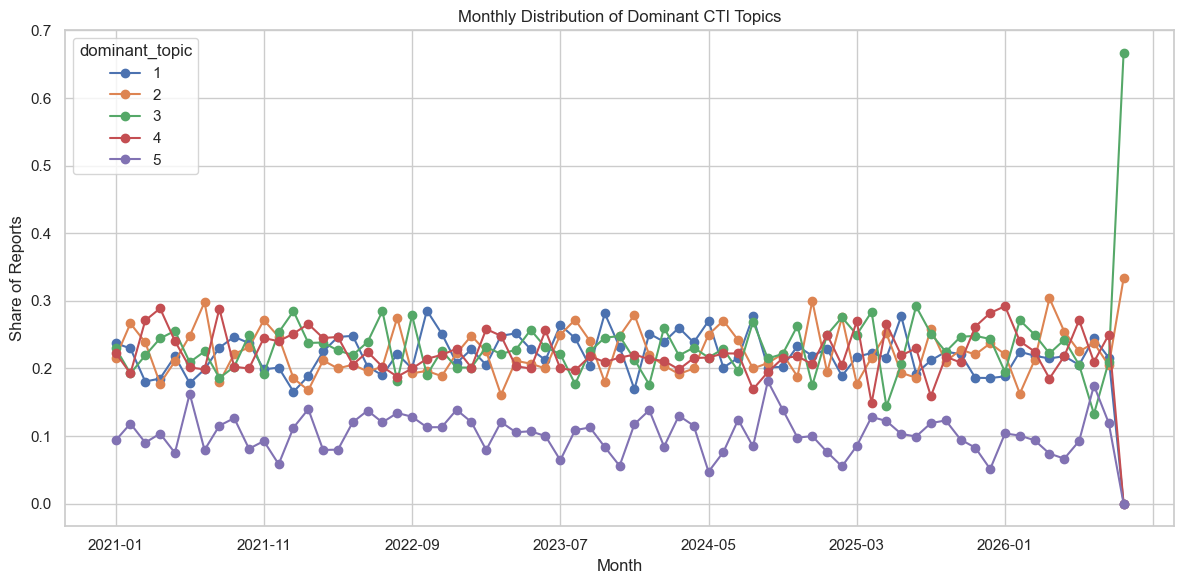

Saved: D:\Projects\done\thesis\ctc_ectd\artifacts\monthly_topic_shares.csv


In [4]:

if len(temporal_df) >= 5:
    vec = TfidfVectorizer(max_features=5000, stop_words="english",
                          ngram_range=(1, 2))
    M = vec.fit_transform(temporal_df["model_text"])
    k = min(5, M.shape[0], M.shape[1])

    if k >= 2:
        nmf = NMF(n_components=k, random_state=RANDOM_STATE,
                  init="nndsvda", max_iter=500)
        W = nmf.fit_transform(M)
        terms = vec.get_feature_names_out()

        for i, comp in enumerate(nmf.components_):
            top = comp.argsort()[-10:][::-1]
            print(f"Topic {i+1}:", ", ".join(terms[j] for j in top))

        for i in range(k):
            temporal_df[f"Topic_{i+1}"] = W[:, i]
        temporal_df["dominant_topic"] = W.argmax(axis=1) + 1

        monthly_topic_counts = pd.crosstab(
            temporal_df["month"], temporal_df["dominant_topic"])
        monthly_topic_shares = monthly_topic_counts.div(
            monthly_topic_counts.sum(axis=1), axis=0).fillna(0)

        display(monthly_topic_shares.round(3))
        monthly_topic_shares.plot(figsize=(12, 6), marker="o")
        plt.title("Monthly Distribution of Dominant CTI Topics")
        plt.xlabel("Month"); plt.ylabel("Share of Reports")
        plt.tight_layout(); plt.show()

        monthly_topic_shares.to_csv(ARTIFACT_DIR / "monthly_topic_shares.csv")
        print("Saved:", ARTIFACT_DIR / "monthly_topic_shares.csv")
    else:
        print("Not enough terms to fit multiple topics.")
else:
    print("Insufficient dated reports for temporal topic modeling.")


## 3. Emerging-threat detection

In [5]:

EMERGING_MIN_SHARE_JUMP = 0.10   # 10 percentage points
EMERGING_MIN_COUNT      = 2

alerts = []
if "monthly_topic_shares" in dir():
    months = list(monthly_topic_shares.index)
    for i in range(1, len(months)):
        prev_m, curr_m = months[i - 1], months[i]
        for tid in monthly_topic_shares.columns:
            ps = monthly_topic_shares.loc[prev_m, tid]
            cs = monthly_topic_shares.loc[curr_m, tid]
            cnt = monthly_topic_counts.loc[curr_m, tid]
            if (cs - ps) >= EMERGING_MIN_SHARE_JUMP and cnt >= EMERGING_MIN_COUNT:
                alerts.append({
                    "Previous Month": prev_m,
                    "Current Month": curr_m,
                    "Topic": tid,
                    "Previous Share": round(ps, 3),
                    "Current Share": round(cs, 3),
                    "Increase (pp)": round(cs - ps, 3),
                    "Current Report Count": cnt,
                })

alerts_df = pd.DataFrame(alerts)
if not alerts_df.empty:
    alerts_df = alerts_df.sort_values("Increase (pp)", ascending=False)
    display(alerts_df)
    alerts_df.to_csv(ARTIFACT_DIR / "emerging_threat_alerts.csv", index=False)
    print("\nSaved alerts to:", ARTIFACT_DIR / "emerging_threat_alerts.csv")
else:
    print("No topic passed the emerging-threat threshold.")
    print("This does not prove absence of emerging threats.")
    pd.DataFrame(columns=["Previous Month", "Current Month", "Topic",
                          "Previous Share", "Current Share",
                          "Increase (pp)", "Current Report Count"]) \
        .to_csv(ARTIFACT_DIR / "emerging_threat_alerts.csv", index=False)


,Previous Month,Current Month,Topic,Previous Share,Current Share,Increase (pp),Current Report Count
2,2026-08,2026-09,3,0.210,0.667,0.456,2
1,2025-04,2025-05,4,0.149,0.266,0.118,37
0,2024-11,2024-12,2,0.188,0.300,0.112,48



Saved alerts to: D:\Projects\done\thesis\ctc_ectd\artifacts\emerging_threat_alerts.csv
